In [1]:
%pip install osmnx


  Using cached osmnx-2.0.7-py3-none-any.whl.metadata (4.9 kB)
  Using cached geopandas-1.1.4-py3-none-any.whl.metadata (2.3 kB)
  Using cached networkx-3.4.2-py3-none-any.whl.metadata (6.3 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached shapely-2.1.2-cp310-cp310-win_amd64.whl.metadata (7.1 kB)
  Using cached pyogrio-0.13.0-cp310-cp310-win_amd64.whl.metadata (6.0 kB)
  Using cached pyproj-3.7.1-cp310-cp310-win_amd64.whl.metadata (31 kB)
  Using cached charset_normalizer-3.5.2-cp310-cp310-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
Using cached osmnx-2.0.7-py3-none-any.whl (101 kB)
Using cached geopandas-1.1.4-py3-none-any.whl (343 kB)
Using cached networkx-3.4.2-py3-none-any.whl (1.7 MB)
   ---------------------------------------- 0.0/23.9 MB ? eta -:--:--
   ---------- ----------------------------- 6.6/23.9 MB 33.5 MB/s eta 0:00:01
   ----

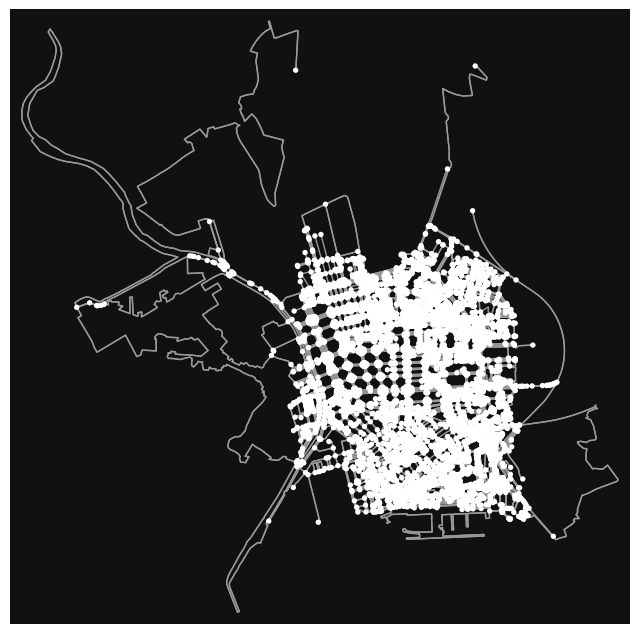

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [4]:
import osmnx as ox

G = ox.graph_from_xml("map2.osm", simplify=True)    # grafo de NetworkX
nodes, edges = ox.graph_to_gdfs(G)                  # a GeoDataFrames
ox.plot_graph(G)

In [8]:
%pip install folium

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.4-cp310-cp310-win_amd64.whl.metadata (2.8 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp310-cp310-win_amd64.whl (14 kB)

   ---------------- ----------------------- 2/5 [jinja2]
   ------------------------ --------------- 3/5 [branca]
   -------------------------------- ------- 4/5 [folium]
   ---------------------------------------- 5/5 [folium]

Note: you may need to restart the kernel to use updated packages.


In [22]:
%pip install folium mapclassify

Note: you may need to restart the kernel to use updated packages.


                     y         x   highway railway                   geometry
osmid                                                                        
30658392     37.597706 -0.986710       NaN     NaN  POINT (-0.98671 37.59771)
30661751     37.598438 -0.974603       NaN     NaN   POINT (-0.9746 37.59844)
30661869     37.597260 -0.982701       NaN     NaN   POINT (-0.9827 37.59726)
30662457     37.597382 -0.974714       NaN     NaN  POINT (-0.97471 37.59738)
30663052     37.597407 -0.989863       NaN     NaN  POINT (-0.98986 37.59741)
...                ...       ...       ...     ...                        ...
14235958274  37.598140 -0.982881       NaN     NaN  POINT (-0.98288 37.59814)
14235958275  37.598104 -0.982878  crossing     NaN   POINT (-0.98288 37.5981)
14235958276  37.597834 -0.982863       NaN     NaN  POINT (-0.98286 37.59783)
14235958277  37.597896 -0.982866  crossing     NaN   POINT (-0.98287 37.5979)
14288355145  37.597402 -0.988309       NaN     NaN   POINT (-0.9

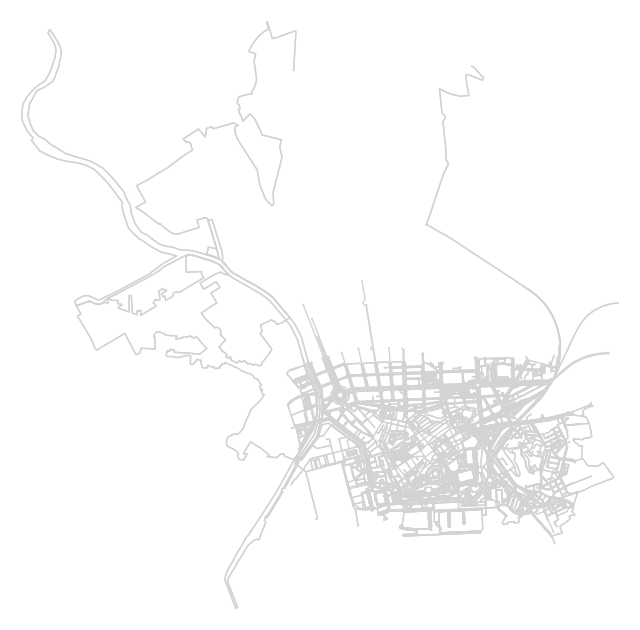

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [24]:
import osmnx as ox

# Cargar el mapa descargado
G = ox.graph_from_xml("map.osm", simplify=True)
nodes, edges = ox.graph_to_gdfs(G)
print(nodes)
# a) Por coordenadas: el nodo de la red más cercano a cada punto que elijáis
#    (ojo: X = longitud, Y = latitud). Las coordenadas se sacan de Google Maps
#    o de openstreetmap.org con clic derecho.
lons = [-0.9865, -0.9790, -0.9912]
lats = [37.6050, 37.6102, 37.6001]
mis_nodos = ox.distance.nearest_nodes(G, X=lons, Y=lats)

# b) Por identificador: mapa interactivo donde, al pasar el ratón por un nodo,
#    se ve su id (osmid); apuntáis los que queráis.
nodes.explore()                    # en un notebook se muestra directamente
mis_nodos = [123456789, 987654321]  # ids de ejemplo: poned los vuestros

# Dibujar la red con los nodos elegidos resaltados
colores = ["red" if n in mis_nodos else "lightgray" for n in G.nodes]
tamanos = [40 if n in mis_nodos else 2 for n in G.nodes]
ox.plot_graph(G, node_color=colores, node_size=tamanos,
              edge_color="lightgray", bgcolor="white")

Nodos en la red: 8718
   id        nodo        lat       lon
0   1  3721796456  37.599614 -0.977941
1   2  2832211406  37.598578 -0.987990
2   3   767434546  37.615596 -0.982512
3   4   767434903  37.601354 -0.986862
4   5  3074184085  37.612072 -0.977395


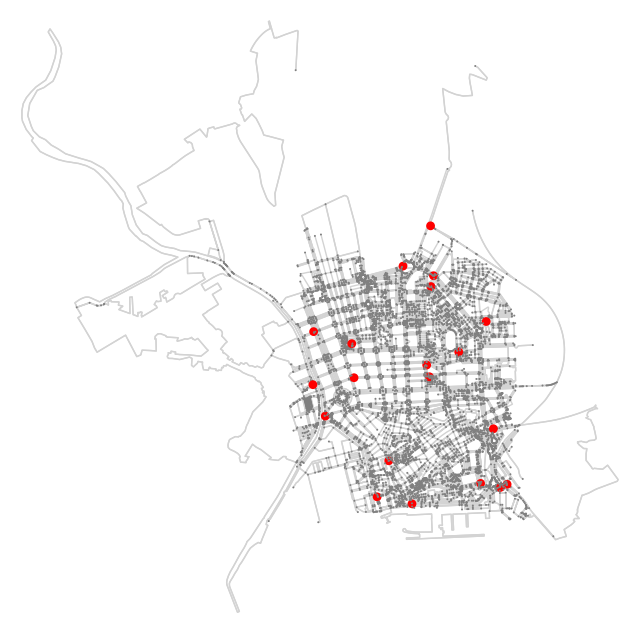

(<Figure size 800x800 with 1 Axes>, <Axes: >)

In [26]:
import random

import osmnx as ox
import pandas as pd

N_NODOS = 20          # cuántos nodos queréis
SEMILLA = 42           # misma semilla = misma selección cada vez (None para que cambie)

G = ox.graph_from_xml("map2.osm", simplify=True)
lista_nodos = list(G.nodes)                 # los ~6100 identificadores de nodo
print(f"Nodos en la red: {len(lista_nodos)}")

# 1) Elegir N_NODOS posiciones al azar con randint, sin repetir ninguna
random.seed(SEMILLA)
posiciones = set()
while len(posiciones) < N_NODOS:
    posiciones.add(random.randint(0, len(lista_nodos) - 1))   # randint incluye ambos extremos
mis_nodos = [lista_nodos[p] for p in sorted(posiciones)]

# 2) Recoger sus coordenadas en una tabla y guardarla
seleccion = pd.DataFrame({
    "id": range(1, N_NODOS + 1),
    "nodo": mis_nodos,                                  # identificador del nodo en OSM
    "lat": [G.nodes[n]["y"] for n in mis_nodos],        # y = latitud
    "lon": [G.nodes[n]["x"] for n in mis_nodos],        # x = longitud
})
seleccion.to_csv("nodos_seleccionados.csv", index=False)
print(seleccion.head())

# 3) Dibujar la red con los nodos elegidos en rojo
elegidos = set(mis_nodos)
colores = ["red" if n in elegidos else "gray" for n in G.nodes]
tamanos = [40 if n in elegidos else 2 for n in G.nodes]
ox.plot_graph(G, node_color=colores, node_size=tamanos, node_zorder=3,
              edge_color="lightgray", bgcolor="white")